# COMP90051 Statistical Machine Learning Project
# Group 38

Group Members:
Michael Allen
, Manan Saddi
, Minh Cao

# 1. Research Question

On consumer credit default data, how do rising class imbalance and feature redundancy affect the calibration of predicted default probabilities relative to ranking power, and does calibration break down before ranking does as the data degrades?

On consumer credit default data, how do ranking and probability calibration respond as the data degrades through greater class imbalance and greater feature redundancy, and does calibration deteriorate faster than ranking does. We study this across three model classes of increasing complexity (L1 logistic regression, gradient boosted trees, and an FT-Transformer).

Note on method. We vary class imbalance and feature redundancy on the training fold only, and we always evaluate on a held out test fold that keeps the true default rate, so calibration is measured against the real world distribution rather than an artificial one.

# 2. Imports

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
# FT-Transformer (complex): pip install rtdl torch
# import torch, rtdl

SEED = 42
np.random.seed(SEED)

# Subset for CV/tuning.
SUBSAMPLE_N = 40_000

pd.set_option("display.max_columns", 80)
plt.rcParams["figure.figsize"] = (7, 4)

# 3. Loading Dataset

Dataset: **Home Credit Default Risk** (Kaggle).
URL: https://www.kaggle.com/competitions/home-credit-default-risk/data


Seven related tables (one applicant = `SK_ID_CURR`):
- `application_train.csv` - main table, one row per loan, `TARGET` (1 = repayment difficulty).
- `bureau.csv` (+ `bureau_balance.csv`) - credits at other institutions.
- `previous_application.csv` - earlier Home Credit applications.
- `POS_CASH_balance.csv`, `installments_payments.csv`, `credit_card_balance.csv` - monthly histories.

The child tables are where we will get marks, aggregating them to applicant level is "complex
feature construction"?

In [2]:
from pathlib import Path

DATA_DIR = Path.cwd()

df = pd.read_csv(DATA_DIR / "application_train.csv")
print("application_train:", df.shape)

ID_COL, TARGET_COL = "SK_ID_CURR", "TARGET"
print("default rate: %.3f%%" % (100 * df[TARGET_COL].mean()))
df.head()

application_train: (307511, 122)
default rate: 8.073%


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,...,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,1,1,0,Laborers,1.0,2,2,WEDNESDAY,10,0,0,0,0,0,0,...,0.0205,0.0193,0.0000,0.00,reg oper account,block of flats,0.0149,"Stone, brick",No,2.0,2.0,2.0,2.0,-1134.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,1,1,0,Core staff,2.0,1,1,MONDAY,11,0,0,0,0,0,0,...,0.0787,0.0558,0.0039,0.01,reg oper account,block of flats,0.0714,Block,No,1.0,0.0,1.0,0.0,-828.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,1,1,0,Laborers,1.0,2,2,MONDAY,9,0,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,-815.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,297000.0,Unaccompanied,Working,Secondary / secondary special,Civil marriage,House / apartment,0.008019,-19005,-3039,-9833.0,-2437,NaN,1,1,0,1,0,0,Laborers,2.0,2,2,WEDNESDAY,17,0,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,0.0,2.0,0.0,-617.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,513000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.028663,-19932,-3038,-4311.0,-3458,NaN,1,1,0,1,0,0,Core staff,1.0,2,2,THURSDAY,11,0,0,0,0,1,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,-1106.0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


# 4. Initial Data Exploration

We are told not to do much exploration so we can keep this brief.

In [3]:
# Target balance
print(df[TARGET_COL].value_counts(normalize=True))

# Missingness (many columns are sparse: EXT_SOURCE_*, building-info blocks)
miss = df.isna().mean().sort_values(ascending=False)
print("\nTop missing columns:\n", miss.head(12))

# Strongest known predictors: the external credit scores
for c in ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]:
    if c in df: print(f"{c}: missing={df[c].isna().mean():.2%}, corr with TARGET={df[c].corr(df[TARGET_COL]):.3f}")
    

# Categorical columns
cat_cols = df.select_dtypes("object").columns.tolist()
print("\nCategorical columns:", len(cat_cols))

TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64

Top missing columns:
 COMMONAREA_AVG              0.698723
COMMONAREA_MODE             0.698723
COMMONAREA_MEDI             0.698723
NONLIVINGAPARTMENTS_MEDI    0.694330
NONLIVINGAPARTMENTS_MODE    0.694330
NONLIVINGAPARTMENTS_AVG     0.694330
FONDKAPREMONT_MODE          0.683862
LIVINGAPARTMENTS_AVG        0.683550
LIVINGAPARTMENTS_MEDI       0.683550
LIVINGAPARTMENTS_MODE       0.683550
FLOORSMIN_MODE              0.678486
FLOORSMIN_AVG               0.678486
dtype: float64
EXT_SOURCE_1: missing=56.38%, corr with TARGET=-0.155
EXT_SOURCE_2: missing=0.21%, corr with TARGET=-0.160
EXT_SOURCE_3: missing=19.83%, corr with TARGET=-0.179

Categorical columns: 16


C:\Users\misha\AppData\Local\Temp\ipykernel_47904\2649344925.py:14: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes("object").columns.tolist()


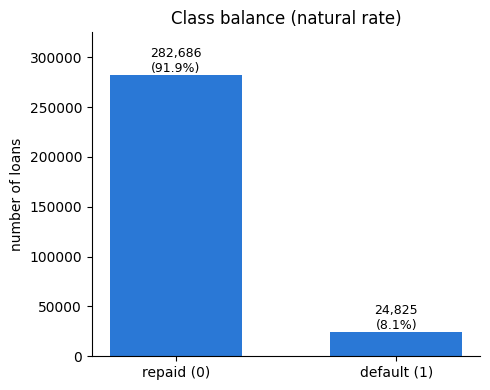

In [4]:
# Class balance (baseline imbalance)
counts = df[TARGET_COL].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(["repaid (0)", "default (1)"], counts.values, color="#2a78d6", width=0.6)
for b, n in zip(bars, counts.values):
    ax.annotate(f"{n:,}\n({n / counts.sum():.1%})", (b.get_x() + b.get_width() / 2, b.get_height()),
                ha="center", va="bottom", fontsize=9)
ax.set_ylabel("number of loans"); ax.set_title("Class balance (natural rate)")
ax.set_ylim(0, counts.max() * 1.15)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

In [5]:
# Feature pairs with the most correlation
num = df.select_dtypes("number").drop(columns=[ID_COL, TARGET_COL])
corr = num.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = upper.stack().sort_values(ascending=False)
print("numeric feature pairs with |corr| > 0.9:", int((pairs > 0.9).sum()))
print(pairs.head(15))

# How separable are the strongest predictors by class (ranking signal)
for c in ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]:
    print(c, "mean by target:", df.groupby(TARGET_COL)[c].mean().round(3).to_dict())

# How sparse defaulters get as you degrade (sanity check for the 1% setting)
n_neg = int((df[TARGET_COL] == 0).sum())
for p in [0.05, 0.02, 0.01]:
    print(f"at {p:.0%} positive, keeping all negatives, you'd have ~{int(p/(1-p)*n_neg)} positives")

numeric feature pairs with |corr| > 0.9: 62
DAYS_EMPLOYED                FLAG_EMP_PHONE                  0.999755
YEARS_BUILD_AVG              YEARS_BUILD_MEDI                0.998495
OBS_30_CNT_SOCIAL_CIRCLE     OBS_60_CNT_SOCIAL_CIRCLE        0.998490
FLOORSMIN_AVG                FLOORSMIN_MEDI                  0.997241
FLOORSMAX_AVG                FLOORSMAX_MEDI                  0.997034
ENTRANCES_AVG                ENTRANCES_MEDI                  0.996886
ELEVATORS_AVG                ELEVATORS_MEDI                  0.996099
COMMONAREA_AVG               COMMONAREA_MEDI                 0.995978
LIVINGAREA_AVG               LIVINGAREA_MEDI                 0.995596
APARTMENTS_AVG               APARTMENTS_MEDI                 0.995081
BASEMENTAREA_AVG             BASEMENTAREA_MEDI               0.994317
LIVINGAPARTMENTS_AVG         LIVINGAPARTMENTS_MEDI           0.993825
YEARS_BEGINEXPLUATATION_AVG  YEARS_BEGINEXPLUATATION_MEDI    0.993825
LANDAREA_AVG                 LANDAREA_MEDI    

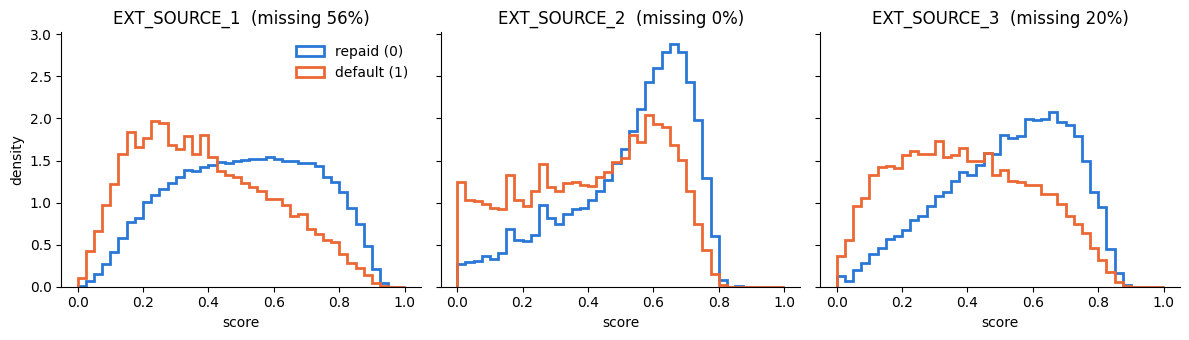

In [6]:
# EXT_SOURCE distributions split by class (density, so the small default class is visible).
# The shift between the two curves is the ranking signal these scores carry.
ext_cols = [c for c in ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"] if c in df]
fig, axes = plt.subplots(1, len(ext_cols), figsize=(4 * len(ext_cols), 3.5), sharey=True)
bins = np.linspace(0, 1, 41)
for ax, c in zip(np.atleast_1d(axes), ext_cols):
    for label, name, color in [(0, "repaid (0)", "#2a78d6"), (1, "default (1)", "#eb6834")]:
        ax.hist(df.loc[df[TARGET_COL] == label, c].dropna(), bins=bins, density=True,
                histtype="step", linewidth=2, color=color, label=name)
    ax.set_title(f"{c}  (missing {df[c].isna().mean():.0%})")
    ax.set_xlabel("score")
    ax.spines[["top", "right"]].set_visible(False)
np.atleast_1d(axes)[0].set_ylabel("density")
np.atleast_1d(axes)[0].legend(frameon=False)
plt.tight_layout(); plt.show()

# 5. Cleaning

Standard cleaning for this dataset

- `DAYS_EMPLOYED == 365243` is a sentinel (~1000 years) for pensioners/unemployed, should be NaN.
- `DAYS_*` are negative (days before application). We should take absolute value for readability.
- `CODE_GENDER == 'XNA'` (only a few rows).
- `ORGANIZATION_TYPE == 'XNA'` (treat as missing?)
- Impute **inside folds**, not here (this cell only fixes structural issues).

In [7]:
# Method for a basic clean
def basic_clean(df):
    df = df.copy()
    if "DAYS_EMPLOYED" in df:
        df["DAYS_EMPLOYED_ANOM"] = (df["DAYS_EMPLOYED"] == 365243).astype(int)
        df["DAYS_EMPLOYED"] = df["DAYS_EMPLOYED"].replace(365243, np.nan)
    for c in [c for c in df.columns if c.startswith("DAYS_")]:
        df[c] = df[c].abs()
    if "CODE_GENDER" in df:
        df["CODE_GENDER"] = df["CODE_GENDER"].replace("XNA", np.nan)
    return df

app_clean = basic_clean(df)
if SUBSAMPLE_N:  # stratified subsample keeps the class ratio (do this early to keep everything fast)
    pos = app_clean[app_clean[TARGET_COL] == 1]
    neg = app_clean[app_clean[TARGET_COL] == 0]
    n_pos = int(SUBSAMPLE_N * app_clean[TARGET_COL].mean())
    app_clean = pd.concat([pos.sample(n_pos, random_state=SEED),
                           neg.sample(SUBSAMPLE_N - n_pos, random_state=SEED)]).sample(frac=1, random_state=SEED)
print("working set:", app_clean.shape)


working set: (40000, 123)


# 6. Feature Construction

Three layers to our feature construction.

A. Multi table aggregation. For each child table, aggregate to one row per `SK_ID_CURR` (counts, mean, sum, min, max of the numeric columns, plus category counts), then left join onto the application table.

B. Domain ratios on the application table. For example, credit to income, annuity to income, credit term, employment length over age, and combinations of the three external scores (the strongest signal).

C. Derived behavioural features. In the payment tables we compute per row signals before aggregating, such as how much less than the instalment was paid and how many days late, then summarise them per applicant. These capture repayment behaviour directly, which is what drives default.

Together this will easily clear the 100 feature requirement from interpretable columns. All the fold fit transforms (imputation, encoding, target based aggregation stats) go inside the FeatureBuilder so nothing leaks.

### 6.1 Helper functions

Small reusable functions for the construction below. `agg_table` summarises a child table to one row per applicant, `cat_counts` counts the categories of one column per applicant, `agg_bureau_balance` does the nested monthly rollup, and `add_domain_ratios` builds interpretable ratios on the main table.

In [ ]:
# Collapses a child table to one row per applicant with numeric summary stats.
def agg_table(child, prefix):
    num = child.select_dtypes("number").drop(
        columns=[c for c in child if c.startswith("SK_ID_") and c != ID_COL], errors="ignore")  # numeric only, drop ID cols
    g = num.groupby(ID_COL) # group an applicant's rows
    out = g.agg(["mean", "min", "max", "sum"]) # summarise each column 4 ways
    out.columns = [f"{prefix}{a}_{b}" for a, b in out.columns] # e.g. BURO_AMT_CREDIT_mean
    out[f"{prefix}COUNT"] = g.size() # how many records the applicant has
    return out.reset_index()

# Counts how many records fall in each category of one column, per applicant.
def cat_counts(child, col, prefix):
    d = pd.get_dummies(child[[ID_COL, col]], columns=[col]).groupby(ID_COL).sum()
    d.columns = [f"{prefix}{c}" for c in d.columns]
    return d.reset_index()

# Nested rollup: bureau_balance has no applicant id, so summarise it per credit (SK_ID_BUREAU) first.
def agg_bureau_balance():
    bb = pd.read_csv(DATA_DIR / "bureau_balance.csv")
    # Groups all monthly rows by credit and computes three things
    num = bb.groupby("SK_ID_BUREAU")["MONTHS_BALANCE"].agg(["min", "max", "size"]) # how far back / how many months
    # This renames the three columns.
    num.columns = ["BB_MONTHS_min", "BB_MONTHS_max", "BB_COUNT"]
    # Keeps two cols, OHE status and adds those indicators up per credit
    status = pd.get_dummies(bb[["SK_ID_BUREAU", "STATUS"]], columns=["STATUS"]).groupby("SK_ID_BUREAU").sum() # status counts
    status.columns = [f"BB_{c}" for c in status.columns]
    return num.join(status).reset_index()

# Builds the interpretable ratios on the main table (credit-to-income, etc., plus EXT_SOURCE mean/std).
def add_domain_ratios(df):
    df = df.copy()
    df["CREDIT_INCOME_RATIO"] = df["AMT_CREDIT"]  / df["AMT_INCOME_TOTAL"].replace(0, np.nan)
    df["ANNUITY_INCOME_RATIO"] = df["AMT_ANNUITY"] / df["AMT_INCOME_TOTAL"].replace(0, np.nan)
    df["CREDIT_TERM"] = df["AMT_ANNUITY"] / df["AMT_CREDIT"].replace(0, np.nan)
    df["DAYS_EMPLOYED_PERC"] = df["DAYS_EMPLOYED"] / df["DAYS_BIRTH"].replace(0, np.nan)
    ext = [c for c in ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"] if c in df]
    if ext:
        df["EXT_SOURCE_MEAN"] = df[ext].mean(axis=1) # consensus external score
        df["EXT_SOURCE_STD"]  = df[ext].std(axis=1) # disagreement between sources
    return df

### 6.2 Build the modelling table

Clean, take a stratified subsample for speed, add the ratios, join all six child tables, then drop dead (constant) columns. Rebuilds from the fresh `df` every run, so re-running won't stack columns.

In [ ]:
# Start from a fresh frame, clean, then stratified subsample that keeps the true class ratio
app_clean = basic_clean(df)
if SUBSAMPLE_N:
    pos = app_clean[app_clean[TARGET_COL] == 1]
    neg = app_clean[app_clean[TARGET_COL] == 0]
    n_pos = int(SUBSAMPLE_N * app_clean[TARGET_COL].mean())
    app_clean = pd.concat([pos.sample(n_pos, random_state=SEED),
                           neg.sample(SUBSAMPLE_N - n_pos, random_state=SEED)]).sample(frac=1, random_state=SEED)

# Adds interpretable ratios on the application table.
app_clean = add_domain_ratios(app_clean)

# Merging bureau & bureau_balance. Little more difficult as there is no application ID to merge on.
bureau = pd.read_csv(DATA_DIR / "bureau.csv")
# Squashes each credit's monthly history into one summary row (how many months, how far back, how many on-time vs late months).
# Merge that onto bureau, so every credit now carries its history summary.
bureau = bureau.merge(agg_bureau_balance(), on="SK_ID_BUREAU", how="left")
# Squashes all of a person's credits into one row per applicant (averages, totals, a count).
app_clean = app_clean.merge(agg_table(bureau, "BURO_"), on=ID_COL, how="left")
# Adds how many of their credits are active vs closed.
app_clean = app_clean.merge(cat_counts(bureau, "CREDIT_ACTIVE", "BURO_"), on=ID_COL, how="left")

# Payment installments. Build per-row payment behaviour first, then aggregate
inst = pd.read_csv(DATA_DIR / "installments_payments.csv")
inst["PAY_SHORTFALL"] = inst["AMT_INSTALMENT"] - inst["AMT_PAYMENT"] # >0 = paid less than owed
inst["PAY_RATIO"] = inst["AMT_PAYMENT"] / inst["AMT_INSTALMENT"].replace(0, np.nan)
inst["DAYS_LATE"] = inst["DAYS_ENTRY_PAYMENT"] - inst["DAYS_INSTALMENT"] # >0 = paid late
inst["LATE_FLAG"] = (inst["DAYS_LATE"] > 0).astype(int)
app_clean = app_clean.merge(agg_table(inst, "INST_"), on=ID_COL, how="left")

# the other 3 child tables, left-joined on applicant id
tables = {
    "PREV_": "previous_application.csv", # earlier Home Credit applications
    "POS_":  "POS_CASH_balance.csv", # monthly POS / cash loan balances
    "CC_":   "credit_card_balance.csv", # monthly credit card balances
}

# Loop over the three tables and flat aggregate each
for prefix, fname in tables.items():
    app_clean = app_clean.merge(agg_table(pd.read_csv(DATA_DIR / fname), prefix), on=ID_COL, how="left")

# category counts from previous_application (kept because they carry default signal, see 6.3)
prev = pd.read_csv(DATA_DIR / "previous_application.csv")
# approved vs refused previous applications (refusal count is a strong default signal)
app_clean = app_clean.merge(cat_counts(prev, "NAME_CONTRACT_STATUS", "PREV_"), on=ID_COL, how="left")
# why each previous application was refused (reason carries signal too)
app_clean = app_clean.merge(cat_counts(prev, "CODE_REJECT_REASON", "PREV_"), on=ID_COL, how="left")

print("after joins:", app_clean.shape)

# drop dead columns only (constant / single-value). Keep correlated ones (redundancy is studied).
feat = app_clean.drop(columns=[ID_COL, TARGET_COL])
constant = feat.columns[feat.nunique(dropna=False) <= 1].tolist()
app_clean = app_clean.drop(columns=constant)
print("dropped constant:", len(constant), "| final:", app_clean.shape)

after joins: (40000, 459)
dropped constant: 1 | final: (40000, 458)


### 6.3 Why we keep only three child categoricals

We aggregate the numeric columns of every child table, but treat categoricals selectively. For each candidate we build its per applicant counts and measure the strongest correlation with default, alongside its number of categories. We keep three, all with a clear risk story and among the strongest signal. `NAME_CONTRACT_STATUS` (0.064) and `CODE_REJECT_REASON` (0.059) from previous applications capture how earlier lenders judged the applicant and why they were refused, and `CREDIT_ACTIVE` (0.039) from the bureau data reflects current debt load. We drop the rest as weaker, more sparse, or both. `CREDIT_CURRENCY` carries almost no signal (0.015), and `CREDIT_TYPE` (0.029) and `NAME_CASH_LOAN_PURPOSE` (0.032) spread a weak signal across 15 and 25 categories, so encoding them would add many sparse columns for little value. This keeps the categorical set small and explainable, which matters for the interpretability our research question relies on.

The check below supports this. For each candidate we build its per-applicant counts and report the category count and the strongest correlation with the target. Note this uses the target for descriptive support only. The choice was made on domain grounds and the model still encodes in-fold, so there is no leakage into training.

In [ ]:
def cat_signal(fname, col):
    t = pd.read_csv(DATA_DIR / fname)
    counts = cat_counts(t, col, "")
    m = app_clean[[ID_COL, TARGET_COL]].merge(counts, on=ID_COL, how="left").fillna(0)
    corr = m.drop(columns=[ID_COL, TARGET_COL]).corrwith(m[TARGET_COL]).abs()
    return {"col": col, "n_cats": int(t[col].nunique()), "max_abs_corr": round(float(corr.max()), 4)}

checks = [
    ("bureau.csv", "CREDIT_ACTIVE"), # kept
    ("previous_application.csv", "NAME_CONTRACT_STATUS"), # kept
    ("previous_application.csv", "CODE_REJECT_REASON"), # kept
    ("bureau.csv", "CREDIT_TYPE"), # dropped
    ("bureau.csv", "CREDIT_CURRENCY"), # dropped
    ("previous_application.csv", "NAME_CASH_LOAN_PURPOSE"), # dropped
]
pd.DataFrame([cat_signal(f, c) for f, c in checks])

c:\Users\misha\myenv\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\misha\myenv\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,col,n_cats,max_abs_corr
0,CREDIT_ACTIVE,4,0.0385
1,NAME_CONTRACT_STATUS,4,0.0640
2,CODE_REJECT_REASON,9,0.0590
3,CREDIT_TYPE,15,0.0286
4,CREDIT_CURRENCY,4,0.0154
5,NAME_CASH_LOAN_PURPOSE,25,0.0324


### 6.4 Features and target

Split the target and id off the fully built table. Per-fold preparation (impute, encode, scale) happens later in `FeatureBuilder`, so `X` stays as a readable DataFrame here.

In [11]:
y = app_clean[TARGET_COL].to_numpy()
X = app_clean.drop(columns=[ID_COL, TARGET_COL])
print("X:", X.shape, "| y positives: %.3f%%" % (100 * y.mean()))

X: (40000, 456) | y positives: 8.072%


### 6.5 Fold-safe preparation (FeatureBuilder)

The construction above is done once, up front, and uses no target, so it cannot leak. The steps that learn from data (impute values, one-hot vocabulary, scaling stats) must be fit on the training fold only and applied to the test fold. That is what `FeatureBuilder` does, and it is what `make_fit_predict` will call inside each CV fold.

transform learns its numbers only from the training rows of a fold, then applies them to that fold's held-out test rows, and gets re-fit fresh every fold.

In [ ]:
# Fold-safe prep: impute, one-hot encode, scale. All stats learned on the TRAIN fold only, then applied unchanged to the test fold, so nothing leaks.
class FeatureBuilder:
    def __init__(self):
        pass

    def _split(self, X):
        # Splits numeric columns vs categorical columns
        return X.select_dtypes("number"), X.select_dtypes(exclude="number")

    # Learns the preparation values (each column's median, the category list, and the mean and spread for scaling) from the training rows only.
    def fit(self, X, y=None):
        num, cat = self._split(X)
        # List of numeric column names
        self.num_cols_ = num.columns.tolist()
        # Each numeric column's median for imputation
        self.medians_ = num.median()

        # One-hot-encodes the categorical cols and remembers them (dummy_na=True adds a "was missing" column per categorical)
        dummies = pd.get_dummies(cat, dummy_na=True)
        self.dummy_cols_ = dummies.columns.tolist()

        # Assembles the final matrix (imputed numerics + dummies), then records each column's average and spread for scaling.
        mat = pd.concat([num.fillna(self.medians_), dummies], axis=1)
        self.feature_names_ = mat.columns.tolist()
        self.means_ = mat.mean() # scaling centre (from train)
        self.stds_ = mat.std().replace(0, 1) # scaling spread (avoid divide-by-zero)
        return self

    # Applies those learned values to any rows, filling blanks, turning categories into 0/1 columns and scaling, to return a clean numeric grid.
    def transform(self, X):
        num, cat = self._split(X)
        # Force the numeric columns to be exactly the training set, in the same order, then fill blanks with median.
        num = num.reindex(columns=self.num_cols_).fillna(self.medians_)
        # The dummies line one-hots the categoricals then forces the categorical columns to the exact training category columns. 
        # Any category not seen in training is dropped, any training category missing here is added as all-zeros so test matrix test matrix aleways has same columns as train.
        dummies = pd.get_dummies(cat, dummy_na=True).reindex(columns=self.dummy_cols_, fill_value=0)
        # Assemble in the exact train column order, then scale with train stats
        mat = pd.concat([num, dummies], axis=1).reindex(columns=self.feature_names_, fill_value=0)
        mat = (mat - self.means_) / self.stds_
        return mat.to_numpy() # numeric array, ready for a model

    def fit_transform(self, X, y=None):
        return self.fit(X, y).transform(X)

In [15]:
fb = FeatureBuilder()
Xt = fb.fit_transform(X)
print(Xt.shape, "All finite:", np.isfinite(Xt).all())

(40000, 594) All finite: True
